# HydroKG v1 re-audit: results

Reads the tables written by `hydrokg reaudit` and shows, in order:

1. Data quality (missing-discharge codes)
2. Model summary: skill, rule rates, burden indices
3. Decomposition of the v1 change into the **fine-tuning effect** and the **correction effect**
4. Paired tests, quadrants and aridity-class bootstrap
5. Skill–trust relation
6. Rule composition, rule validity and low-flow-floor sensitivity
7. Independent hydrologic signatures
8. Summary figure

Models: `baseline` (original LSTM), `v1_finetuned` (v1 fine-tuning, before correction),
`v1_final` (v1 fine-tuning + v1 post-hoc correction). ΔV > 0 means fewer violations.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy import stats

RESULTS = Path("/bighome/hdagne1/LSTM-Auditing-HydroKG-v2/results/reaudit_v1")
A = RESULTS / "analysis"
MODELS = {"baseline_test": "baseline", "v1_finetuned_test": "v1_finetuned", "v1_final_test": "v1_final"}
RULES = ["R0", "R1", "R2", "R3", "R4", "R5", "R6"]
INDICES = ["V_phys", "V_err", "V_b"]

pd.set_option("display.width", 200, "display.max_columns", 40, "display.precision", 3)

def read(name, **kw):
    path = A / f"{name}.csv"
    if not path.exists():
        print(f"(not available: {path.name})")
        return None
    return pd.read_csv(path, **kw)

def show(title, table):
    display(Markdown(f"**{title}**"))
    if table is not None:
        display(table)

assert A.exists(), f"Analysis folder not found: {A}"
print("Tables found:", len(list(A.glob('*.csv'))))

Tables found: 23


## 1. Data quality

In [2]:
for f in sorted((RESULTS / "predictions").glob("*_missing.csv")):
    m = pd.read_csv(f)
    coded = m[m["n_missing_code"] > 0]
    print(f"{f.stem.replace('_missing', ''):14s} basins with -999 codes (masked): {len(coded):3d}   days: "
          f"{int(coded['n_missing_code'].sum()):5d}   | basins with NaN days: {int((m['n_nan'] > 0).sum()):3d}")

baseline       basins with -999 codes (masked):   8   days:  2681   | basins with NaN days:   2
v1_final       basins with -999 codes (masked):   8   days:  2681   | basins with NaN days:   2
v1_finetuned   basins with -999 codes (masked):   8   days:  2681   | basins with NaN days:   2


## 2. Model summary (test period, 670 basins)

In [3]:
s = read("model_summary").set_index("model").rename(index=MODELS)
cols = (["n_basins", "kge_median", "nse_median"] + [f"rate_{r}_mean" for r in RULES]
        + [f"{v}_mean" for v in INDICES] + [f"{v}_median" for v in INDICES])
summary = s.loc[list(MODELS.values()), cols]
summary.columns = [c.replace("_mean", " (mean)").replace("_median", " (median)") for c in summary.columns]
show("Skill, mean rule rates and burden indices", summary.T)

**Skill, mean rule rates and burden indices**

model,baseline,v1_finetuned,v1_final
n_basins,670.000,670.000,670.000
kge (median),0.687,0.725,0.723
nse (median),0.674,0.695,0.740
rate_R0 (mean),0.070,0.023,0.000
rate_R1 (mean),0.094,0.049,0.049
rate_R2 (mean),0.047,0.017,0.011
rate_R3 (mean),0.195,0.159,0.082
rate_R4 (mean),0.243,0.237,0.237
rate_R5 (mean),0.010,0.006,0.006
rate_R6 (mean),0.038,0.015,0.033


## 3. Fine-tuning effect vs correction effect

Per basin: fine-tuning = `v1_finetuned − baseline`; correction = `v1_final − v1_finetuned`;
total = `v1_final − baseline`. The correction step of v1 used test-period observations.

In [4]:
ft = read("v1_finetuned_test_vs_baseline_basin_deltas", index_col=0)
fi = read("v1_final_test_vs_baseline_basin_deltas", index_col=0)
metrics = ["d_kge"] + [f"d_{v}" for v in INDICES]
effects = {"fine-tuning": ft[metrics], "correction": fi[metrics] - ft[metrics], "total": fi[metrics]}

rows = []
for effect, d in effects.items():
    for m in metrics:
        x = d[m].dropna()
        nz = x[x != 0]
        p = stats.wilcoxon(nz).pvalue if len(nz) >= 10 else np.nan
        rows.append({"effect": effect, "metric": m, "n": len(x), "mean": x.mean(), "median": x.median(),
                     "share_improved": (x > 0).mean(), "share_worse": (x < 0).mean(), "wilcoxon_p": p})
decomp = pd.DataFrame(rows).set_index(["metric", "effect"]).sort_index()
show("Decomposition (positive = better: higher KGE, fewer violations)", decomp)

share_of_total = (effects["correction"].mean() / effects["total"].mean()).rename("correction share of total mean change")
show("Share of the total mean change produced by the correction step", share_of_total.to_frame())

**Decomposition (positive = better: higher KGE, fewer violations)**

n       mean  median  share_improved  share_worse  wilcoxon_p
metric   effect                                                                      
d_V_b    correction   670  1.037e-02   0.002           0.670        0.321   1.973e-20
         fine-tuning  670  2.604e-02   0.012           0.740        0.258   1.072e-48
         total        670  3.641e-02   0.017           0.766        0.234   3.804e-58
d_V_err  correction   670  2.069e-02   0.007           0.739        0.252   4.482e-44
         fine-tuning  670  2.948e-02   0.013           0.709        0.290   1.364e-40
         total        670  5.017e-02   0.022           0.757        0.243   1.723e-56
d_V_phys correction   670  1.403e-03   0.000           0.291        0.063   1.277e-08
         fine-tuning  670  2.496e-02   0.001           0.582        0.106   5.261e-46
         total        670  2.636e-02   0.002           0.613        0.049   2.411e-48
d_kge    correction   670  6.331e-05  -0.015           0.288        0.707   4.862e-13
         fine-tuning  670  5.309e-02   0.039           0.703        0.297   2.744e-32
         total        670  5.316e-02   0.031           0.643        0.357   1.930e-22

**Share of the total mean change produced by the correction step**

,correction share of total mean change
d_kge,0.001
d_V_phys,0.053
d_V_err,0.412
d_V_b,0.285


## 4. Paired tests, quadrants and aridity classes

In [5]:
for label, name in [("v1_finetuned vs baseline", "v1_finetuned_test_vs_baseline"),
                    ("v1_final vs baseline", "v1_final_test_vs_baseline")]:
    display(Markdown(f"### {label}"))
    show("Wilcoxon signed-rank tests (|r-1|, |alpha-1|, |beta-1|: KGE components)",
         read(f"{name}_paired_tests", index_col=0))
    for v in INDICES:
        q = read(f"{name}_quadrants_{v}", header=[0, 1], index_col=0)
        if q is not None:
            show(f"Share of basins by quadrant: rows ΔKGE, columns Δ{v}", q["share"])
    show("Bootstrap 95 % CI of mean change by aridity class",
         read(f"{name}_bootstrap_by_aridity", index_col=[0, 1]))

### v1_finetuned vs baseline

**Wilcoxon signed-rank tests (|r-1|, |alpha-1|, |beta-1|: KGE components)**

,metric,n,median_diff,p,share_kge_improved
0,kge,670,0.039,2.744e-32,0.703
1,V_b,669,-0.012,1.075e-48,0.703
2,V_phys,461,-0.018,5.248e-46,0.703
3,V_err,669,-0.013,1.362e-40,0.703
4,V_equal_rules,669,-0.012,8.650e-54,0.703
5,V_equal_classes,669,-0.012,1.075e-48,0.703
6,|r-1|,670,-0.008,4.012e-28,0.703
7,|alpha-1|,670,-0.036,1.976e-22,0.703
8,|beta-1|,670,-0.017,1.990e-08,0.703


**Share of basins by quadrant: rows ΔKGE, columns ΔV_phys**

consistency,improved,unchanged,worse
skill,,,
improved,0.422,0.201,0.079
unchanged,0.000,0.000,0.000
worse,0.160,0.110,0.027


**Share of basins by quadrant: rows ΔKGE, columns ΔV_err**

... (12 outputs left out)

**Share of basins by quadrant: rows ΔKGE, columns ΔV_b**

consistency,improved,unchanged,worse
skill,,,
improved,0.509,0.0,0.134
unchanged,0.000,0.0,0.000
worse,0.257,0.0,0.100


**Bootstrap 95 % CI of mean change by aridity class**

n   mean         lo     hi
d_kge    arid        54.0  0.224  1.385e-01  0.322
         humid       57.0 -0.007 -2.039e-02  0.007
         semi_arid  180.0  0.065  4.177e-02  0.092
         sub_humid  379.0  0.032  2.393e-02  0.041
d_V_b    arid        54.0  0.076  4.920e-02  0.103
         humid       57.0  0.002 -4.762e-03  0.009
         semi_arid  180.0  0.065  5.423e-02  0.075
         sub_humid  379.0  0.023  1.939e-02  0.026
d_V_phys arid        54.0  0.050  2.592e-02  0.075
         humid       57.0  0.014 -3.054e-04  0.030
         semi_arid  180.0  0.049  3.897e-02  0.058
         sub_humid  379.0  0.014  1.027e-02  0.018
d_V_err  arid        54.0  0.108  7.009e-02  0.146
         humid       57.0 -0.007 -1.249e-02 -0.002
         semi_arid  180.0  0.090  7.553e-02  0.105
         sub_humid  379.0  0.031  2.680e-02  0.036

## 5. Skill–trust relation (baseline)

In [6]:
show("Spearman correlation of KGE with each index; partial correlation given aridity",
     read("skill_trust_correlation", index_col=0))
show("Violation burden V_b within KGE bins", read("skill_trust_dispersion_by_kge_bin", index_col=0))

**Spearman correlation of KGE with each index; partial correlation given aridity**

,index,n,spearman_rho,spearman_p,variance_shared,partial_rho_given_aridity,partial_p
0,V_b,670,-0.468,7.612e-38,0.219,-0.217,1.417e-08
1,V_phys,670,-0.364,2.314e-22,0.132,-0.248,8.392e-11
2,V_err,670,-0.529,1.103e-49,0.280,-0.302,1.317e-15
3,V_equal_rules,670,-0.521,6.994e-48,0.271,-0.310,2.166e-16
4,V_equal_classes,670,-0.468,7.612e-38,0.219,-0.217,1.417e-08
5,V_b | aridity=arid,54,-0.535,3.107e-05,NaN,NaN,NaN
6,V_b | aridity=humid,57,-0.129,3.389e-01,NaN,NaN,NaN
7,V_b | aridity=semi_arid,180,-0.354,1.088e-06,NaN,NaN,NaN
8,V_b | aridity=sub_humid,379,-0.317,2.658e-10,NaN,NaN,NaN


**Violation burden V_b within KGE bins**

,n,V_p10,V_p50,V_p90,p90_over_p10
bin,,,,,
"(-1.0, 0.0]",17,0.144,0.225,0.398,2.767
"(0.0, 0.2]",31,0.116,0.227,0.378,3.250
"(0.2, 0.4]",49,0.084,0.156,0.264,3.147
"(0.4, 0.5]",31,0.067,0.112,0.188,2.815
"(0.5, 0.6]",77,0.043,0.107,0.201,4.718
"(0.6, 0.7]",148,0.043,0.086,0.170,3.935
"(0.7, 0.8]",174,0.039,0.070,0.166,4.201
"(0.8, 0.9]",128,0.029,0.057,0.158,5.381
"(0.9, 1.0]",11,0.048,0.091,0.114,2.361


## 6. Rule composition, validity and sensitivity (baseline)

In [7]:
show("Average share of each rule in the scalar index", read("index_rule_shares", index_col=0))
show("Class shares by aridity class (normalized rates)", read("class_shares_by_aridity", index_col=0))
show("Class shares by land-cover group (normalized rates)", read("class_shares_by_landcover", index_col=0))
show("Daily-rule co-occurrence P(column | row)", read("daily_rule_cooccurrence", index_col=0))
show("Observation-free rules applied to OBSERVED discharge (false-alarm rates)",
     read("rule_validity_on_observations", index_col=0))
fs = read("low_flow_floor_sensitivity")
if fs is not None:
    show("R1–R3 mean rates vs low-flow floor fraction f (q_floor = max(0.01, f · mean Q_obs,train))",
         fs.pivot_table(index="fraction_of_mean", columns="aridity_class", values=["rate_R1", "rate_R3"]))

**Average share of each rule in the scalar index**

,equal_rules,equal_classes
R0,0.060,0.100
R1,0.098,0.054
R2,0.039,0.021
R3,0.275,0.149
R4,0.474,0.631
R5,0.015,0.012
R6,0.040,0.032


**Class shares by aridity class (normalized rates)**

,PhysicalImpossibility,MagnitudeFailure,TimingFailure,BudgetFailure
group,,,,
arid,1.911e-01,0.274,0.502,0.033
humid,6.759e-04,0.060,0.654,0.286
semi_arid,1.995e-01,0.258,0.488,0.055
sub_humid,1.150e-01,0.254,0.598,0.032


**Class shares by land-cover group (normalized rates)**

,PhysicalImpossibility,MagnitudeFailure,TimingFailure,BudgetFailure
group,,,,
CL/NVM,0.195,0.325,0.465,0.015
DBF,0.050,0.216,0.683,0.052
EF,0.069,0.123,0.685,0.122
GL,0.180,0.228,0.518,0.074
MF,0.150,0.231,0.599,0.020
WS+SL,0.204,0.326,0.436,0.034
unknown,0.000,0.256,0.744,0.000


... (2 outputs left out)

**Observation-free rules applied to OBSERVED discharge (false-alarm rates)**

,count,mean,std,min,25%,50%,75%,max
obs_rate_R0,670.0,0.000,0.000,0.0,0.0,0.0,0.0,0.0
obs_rate_R5,657.0,0.030,0.126,0.0,0.0,0.0,0.0,1.0
obs_rate_R6,670.0,0.054,0.167,0.0,0.0,0.0,0.0,1.0


**R1–R3 mean rates vs low-flow floor fraction f (q_floor = max(0.01, f · mean Q_obs,train))**

rate_R1                            rate_R3                           
aridity_class       arid  humid semi_arid sub_humid    arid  humid semi_arid sub_humid
fraction_of_mean                                                                      
0.00               0.211  0.006     0.191     0.085   0.368  0.053     0.278     0.196
0.01               0.211  0.004     0.190     0.084   0.368  0.052     0.278     0.194
0.05               0.200  0.004     0.172     0.056   0.356  0.042     0.261     0.164
0.10               0.190  0.004     0.151     0.039   0.339  0.035     0.230     0.137
0.20               0.169  0.004     0.123     0.024   0.290  0.031     0.183     0.104

## 7. Independent hydrologic signatures (median absolute error)

In [8]:
for m in ("v1_finetuned_test", "v1_final_test"):
    show(MODELS[m], read(f"{m}_signature_abs_error_change", index_col=0))

**v1_finetuned**

,baseline_median_abs_error,model_median_abs_error
err_runoff_ratio,0.038,0.032
err_evaporative_idx,0.038,0.032
err_fdc_mid_slope,0.661,0.540
err_baseflow_index,0.054,0.043
err_zero_flow_freq,0.004,0.000
err_q5,0.697,0.701
err_q95,0.131,0.136


**v1_final**

,baseline_median_abs_error,model_median_abs_error
err_runoff_ratio,0.038,0.035
err_evaporative_idx,0.038,0.035
err_fdc_mid_slope,0.661,1.118
err_baseflow_index,0.054,0.044
err_zero_flow_freq,0.004,0.000
err_q5,0.697,0.669
err_q95,0.131,0.162


## 8. Summary figure: ranked basin changes

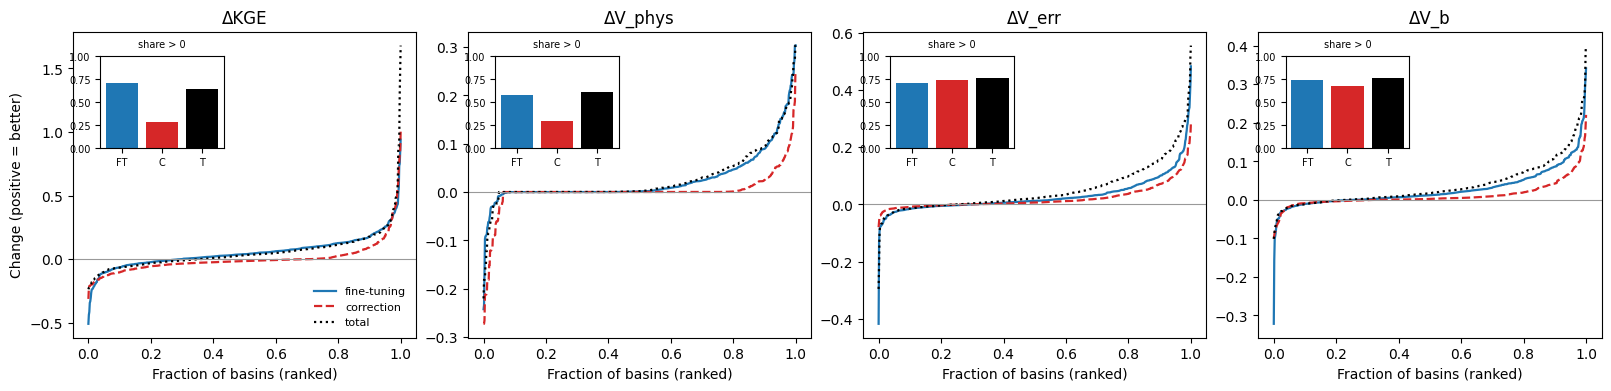

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), constrained_layout=True)
styles = {"fine-tuning": ("tab:blue", "-"), "correction": ("tab:red", "--"), "total": ("black", ":")}
for ax, m in zip(axes, metrics):
    for effect, d in effects.items():
        x = np.sort(d[m].dropna().to_numpy())
        color, ls = styles[effect]
        ax.plot(np.linspace(0, 1, len(x)), x, color=color, ls=ls, lw=1.6, label=effect)
    ax.axhline(0, color="0.6", lw=0.8)
    ax.set_title(m.replace("d_", "Δ").replace("kge", "KGE"))
    ax.set_xlabel("Fraction of basins (ranked)")
    ins = ax.inset_axes([0.08, 0.62, 0.36, 0.3])
    shares = [(effects[e][m] > 0).mean() for e in effects]
    ins.bar(range(3), shares, color=[styles[e][0] for e in effects])
    ins.set_xticks(range(3), ["FT", "C", "T"], fontsize=7)
    ins.set_ylim(0, 1); ins.tick_params(labelsize=7); ins.set_title("share > 0", fontsize=7)
axes[0].set_ylabel("Change (positive = better)")
axes[0].legend(loc="lower right", fontsize=8, frameon=False)
plt.show()

In [12]:
import pandas as pd

A = "/bighome/hdagne1/LSTM-Auditing-HydroKG-v2/results/reaudit_v1/analysis/"

s = pd.read_csv(A + "model_summary.csv", index_col=0).set_index("model")
print(s[["kge_median", "V_b_mean", "V_phys_mean"]].round(3))

for m in ("v1_finetuned_test", "v1_final_test"):
    t = pd.read_csv(A + f"{m}_vs_baseline_paired_tests.csv", index_col=0)
    print(m, "share of basins with higher KGE:", round(t["share_kge_improved"].iloc[0], 3))

                   kge_median  V_b_mean  V_phys_mean
model                                               
baseline_test           0.687     0.112        0.039
v1_final_test           0.723     0.076        0.013
v1_finetuned_test       0.725     0.086        0.014
v1_finetuned_test share of basins with higher KGE: 0.703
v1_final_test share of basins with higher KGE: 0.643


In [14]:
import os, pickle
import numpy as np
import pandas as pd
os.chdir("/bighome/hdagne1/LSTM-Auditing-HydroKG-v2")

from hydrokg.config import load_config
from hydrokg.metrics.skill import skill_table
from hydrokg.metrics.burden import burden_table
from hydrokg.metrics import stats

pd.set_option("display.width", 200)
R = "results/hydrokg_v2_original_baseline/temporal/seed_658666/"
cfg = load_config("configs/experiments/temporal_original_baseline.yaml")

models = ["baseline_test", "baseline+clip_test", "baseline+analog_test",
          "control_test", "control+clip_test", "control+analog_test"]
frames = {}
for m in models:
    with open(R + f"predictions/{m}.p", "rb") as fp:
        preds = pickle.load(fp)
    audit = pd.read_csv(R + f"audits/{m}.csv", index_col=0)
    audit.index = audit.index.astype(str).str.zfill(8)
    frames[m] = skill_table(preds).join(burden_table(audit, cfg)).join(audit[["aridity_class"]])

# 1. summary per model
rows = []
for m, f in frames.items():
    rows.append({"model": m, "KGE_median": f.kge.median(), "KGE_mean": f.kge.mean(),
                 **{f"R{i}": f[f"rate_R{i}"].mean() for i in range(7)},
                 "V_phys": f.V_phys.mean(), "V_err": f.V_err.mean(), "V_b": f.V_b.mean()})
summary = pd.DataFrame(rows).set_index("model").round(3)
display(summary)

# 2. control vs baseline
b, c = frames["baseline_test"], frames["control_test"]
d_kge = c.kge - b.kge
print("Share of basins with higher KGE under control: %.1f %%" % (100 * (d_kge > 0).mean()))
print("Median dKGE: %.4f" % d_kge.median())
print("Wilcoxon:", stats.paired_test(b.kge, c.kge))

# 3. quadrants: dKGE x reduction in V_b (positive = fewer violations)
display(stats.quadrant_table(d_kge, b.V_b - c.V_b)["share"].round(3))

# 4. by aridity class
display(d_kge.groupby(b.aridity_class).agg(["mean", "median", "count"]).round(3))

,KGE_median,KGE_mean,R0,R1,R2,R3,R4,R5,R6,V_phys,V_err,V_b
model,,,,,,,,,,,,
baseline_test,0.687,0.613,0.070,0.094,0.047,0.195,0.244,0.010,0.038,0.039,0.145,0.112
baseline+clip_test,0.687,0.620,0.000,0.094,0.047,0.158,0.244,0.010,0.038,0.016,0.136,0.092
baseline+analog_test,0.685,0.617,0.000,0.075,0.027,0.161,0.245,0.010,0.038,0.016,0.127,0.089
control_test,0.719,0.646,0.007,0.042,0.005,0.178,0.237,0.008,0.017,0.011,0.115,0.083
control+clip_test,0.719,0.646,0.000,0.042,0.005,0.175,0.237,0.008,0.017,0.008,0.115,0.081
control+analog_test,0.719,0.645,0.000,0.039,0.003,0.176,0.237,0.008,0.017,0.008,0.114,0.081


Share of basins with higher KGE under control: 66.1 %
Median dKGE: 0.0289
Wilcoxon: {'n': 670, 'median_diff': 0.028885119563650197, 'p': 1.9608832488649107e-22}


consistency,improved,unchanged,worse
skill,,,
improved,0.513,0.001,0.146
unchanged,0.000,0.000,0.000
worse,0.242,0.000,0.097


,mean,median,count
aridity_class,,,
arid,0.018,0.058,54
humid,-0.009,-0.012,57
semi_arid,0.062,0.062,180
sub_humid,0.028,0.026,379
